(1287, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1287 entries, 0 to 1286
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   REPORTING_PERIOD_START  1287 non-null   object 
 1   REPORTING_PERIOD_END    1287 non-null   object 
 2   GROUP_TYPE              1287 non-null   object 
 3   ORG_CODE1               1287 non-null   object 
 4   ORG_NAME1               1287 non-null   object 
 5   ORG_CODE2               1287 non-null   object 
 6   ORG_NAME2               1287 non-null   object 
 7   MEASURE_ID              1287 non-null   object 
 8   MEASURE_NAME            1287 non-null   object 
 9   MEASURE_VALUE           1273 non-null   float64
dtypes: float64(1), object(9)
memory usage: 100.7+ KB
0
['all SubICBs' 'Unknown' 'LONDON COMMISSIONING REGION'
 'SOUTH WEST COMMISSIONING REGION' 'SOUTH EAST COMMISSIONING REGION'
 'MIDLANDS COMMISSIONING REGION' 'EAST OF ENGLAND COMMISSIONING RE

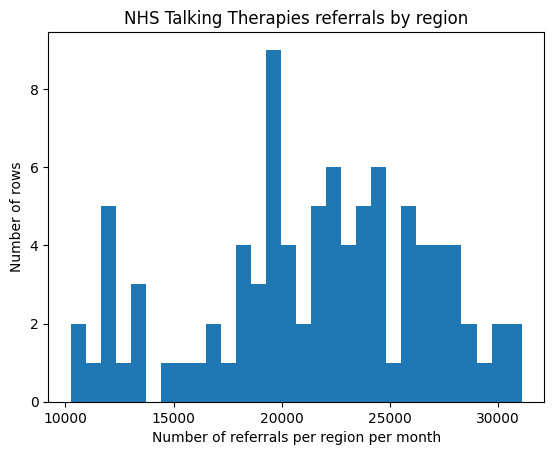

Median: 22095.0
Middle half: 18732.5 to 25685.0


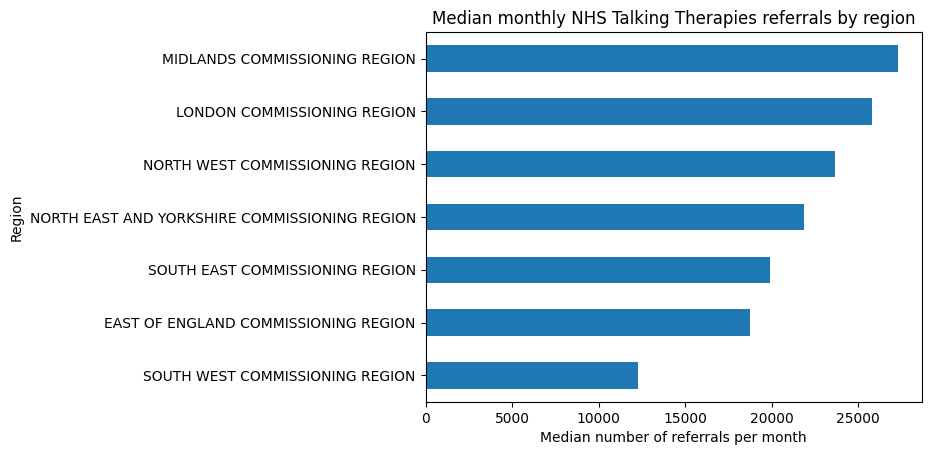

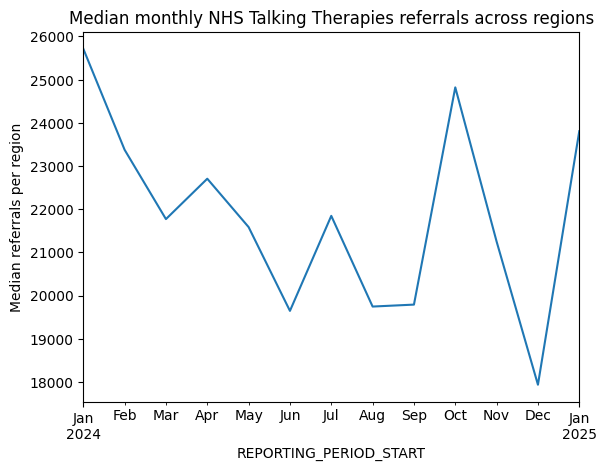

0 rows outside the fences
(1287, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1287 entries, 0 to 1286
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   REPORTING_PERIOD_START  1287 non-null   object 
 1   REPORTING_PERIOD_END    1287 non-null   object 
 2   GROUP_TYPE              1287 non-null   object 
 3   ORG_CODE1               1287 non-null   object 
 4   ORG_NAME1               1287 non-null   object 
 5   ORG_CODE2               1287 non-null   object 
 6   ORG_NAME2               1287 non-null   object 
 7   MEASURE_ID              1287 non-null   object 
 8   MEASURE_NAME            1287 non-null   object 
 9   MEASURE_VALUE           1273 non-null   float64
dtypes: float64(1), object(9)
memory usage: 100.7+ KB
0
['all SubICBs' 'Unknown' 'LONDON COMMISSIONING REGION'
 'SOUTH WEST COMMISSIONING REGION' 'SOUTH EAST COMMISSIONING REGION'
 'MIDLANDS COMMISSIONING REGION' 'EAST O

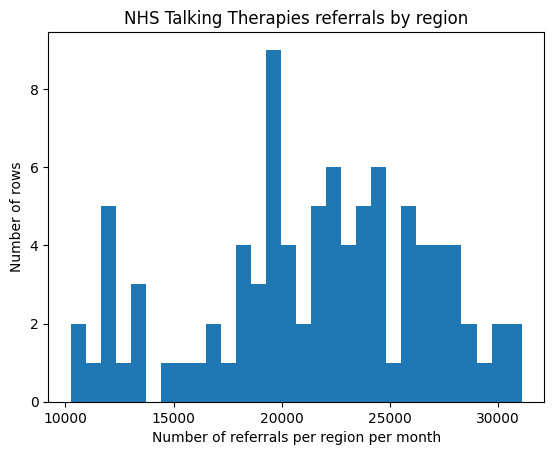

Median: 22095.0
Middle half: 18732.5 to 25685.0


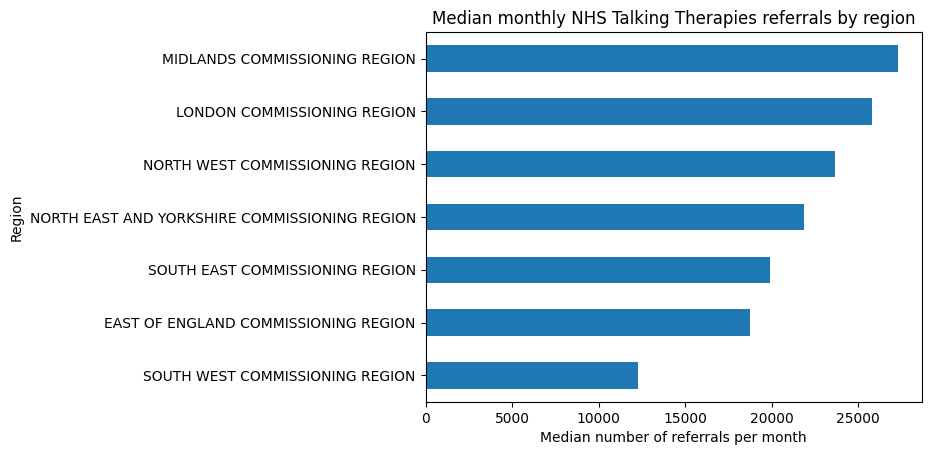

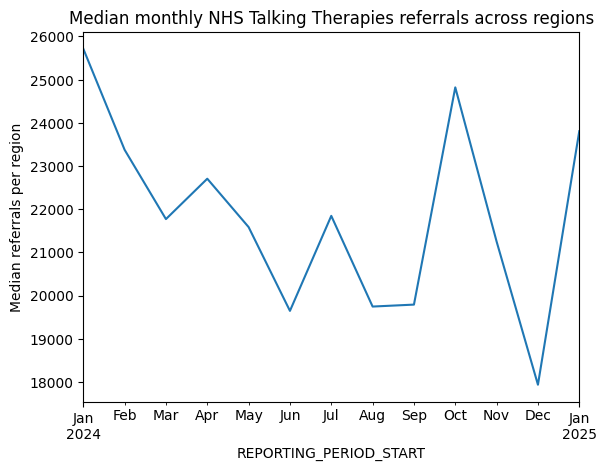

0 rows outside the fences
(1287, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1287 entries, 0 to 1286
Data columns (total 10 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   REPORTING_PERIOD_START  1287 non-null   object 
 1   REPORTING_PERIOD_END    1287 non-null   object 
 2   GROUP_TYPE              1287 non-null   object 
 3   ORG_CODE1               1287 non-null   object 
 4   ORG_NAME1               1287 non-null   object 
 5   ORG_CODE2               1287 non-null   object 
 6   ORG_NAME2               1287 non-null   object 
 7   MEASURE_ID              1287 non-null   object 
 8   MEASURE_NAME            1287 non-null   object 
 9   MEASURE_VALUE           1273 non-null   float64
dtypes: float64(1), object(9)
memory usage: 100.7+ KB
0
['all SubICBs' 'Unknown' 'LONDON COMMISSIONING REGION'
 'SOUTH WEST COMMISSIONING REGION' 'SOUTH EAST COMMISSIONING REGION'
 'MIDLANDS COMMISSIONING REGION' 'EAST O

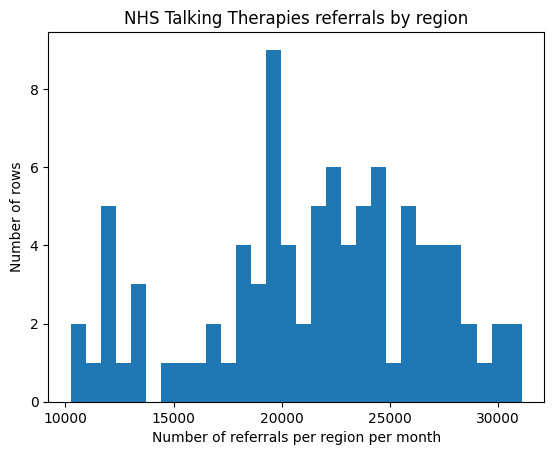

Median: 22095.0
Middle half: 18732.5 to 25685.0


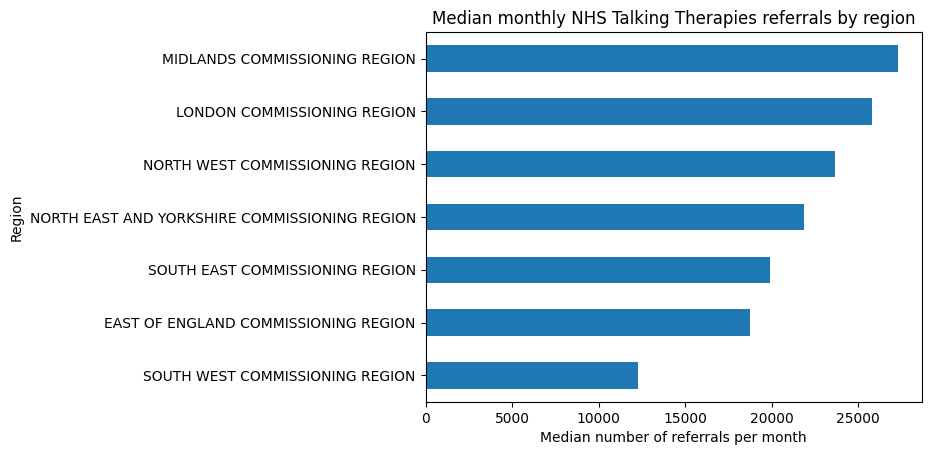

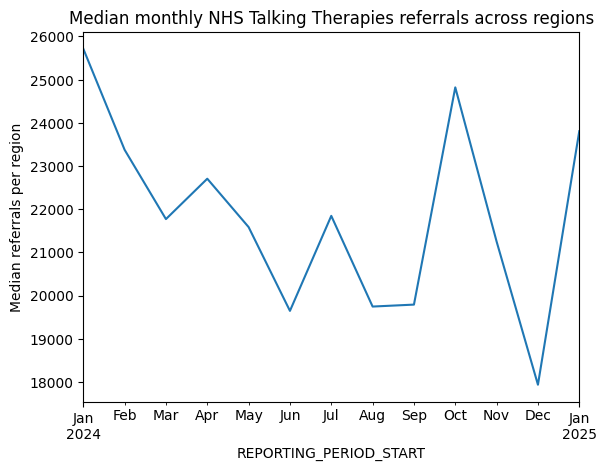

0 rows outside the fences


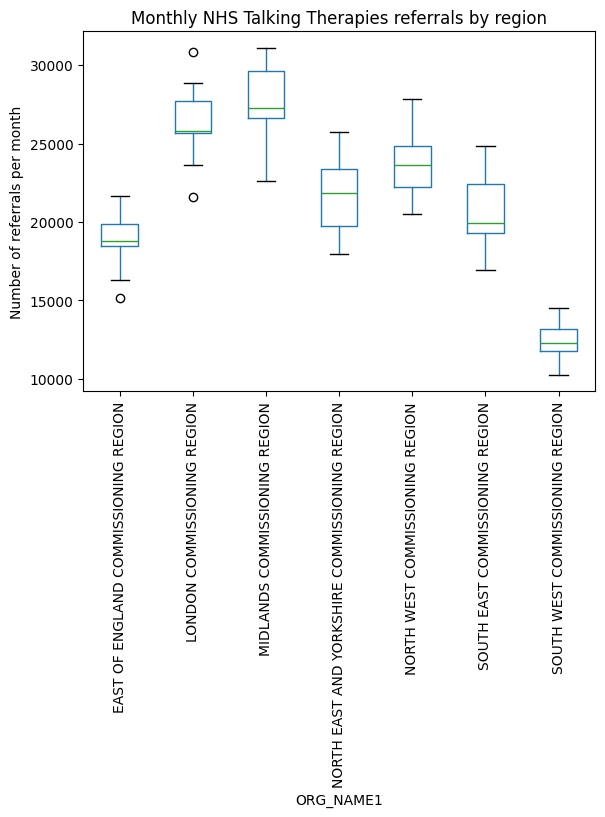

In [3]:
import pandas as pd
data = pd.read_csv("nhs_talking_therapies_regions_2024_2025.csv", na_values=["*"])
data.head()
print(data.shape)
data.info()
data.describe()
data.isna().sum()
data = data.dropna(subset=["MEASURE_VALUE"])
data.isna().sum()
print(data.duplicated().sum())
data = data.drop_duplicates()
print(data["ORG_NAME1"].unique())
data["ORG_NAME1"] = data["ORG_NAME1"].str.strip()
data.info()
data["MEASURE_VALUE"].describe()
data["REPORTING_PERIOD_START"] = pd.to_datetime(data["REPORTING_PERIOD_START"], format="%Y-%m-%d")
data["REPORTING_PERIOD_END"] = pd.to_datetime(data["REPORTING_PERIOD_END"], format="%Y-%m-%d")
data.info()
data = data[data["MEASURE_VALUE"] >= 0]
print(data.shape)
data.to_csv("nhs_talking_therapies_clean.csv", index=False)
print("Saved", len(data), "rows to nhs_talking_therapies_clean.csv")
import matplotlib.pyplot as plt
referrals = data[
(data["MEASURE_NAME"] == "Count_ReferralsReceived")
& (data["GROUP_TYPE"] == "CommissioningRegion")
& (data["ORG_NAME1"] != "Unknown")
].copy()
print(referrals.shape)
referrals ["MEASURE_VALUE"].plot(kind="hist", bins=30, title="NHS Talking Therapies referrals by region")
plt.xlabel("Number of referrals per region per month")
plt.ylabel("Number of rows")
plt.show()
print("Median:", referrals["MEASURE_VALUE"].median())
print("Middle half:", referrals["MEASURE_VALUE"].quantile(0.25), "to", referrals["MEASURE_VALUE"].quantile(0.75))
by_group = referrals.groupby("ORG_NAME1")["MEASURE_VALUE"].median().sort_values()
by_group.plot(kind="barh", title="Median monthly NHS Talking Therapies referrals by region")
plt.xlabel("Median number of referrals per month")
plt.ylabel("Region")
plt.show()
referrals["REPORTING_PERIOD_START"] = pd.to_datetime(referrals["REPORTING_PERIOD_START"])
monthly = referrals.set_index("REPORTING_PERIOD_START")["MEASURE_VALUE"].resample("MS").median()
monthly.plot(title="Median monthly NHS Talking Therapies referrals across regions")
plt.ylabel("Median referrals per region")
plt.show()
q1 = referrals["MEASURE_VALUE"].quantile(0.25)
q3 = referrals["MEASURE_VALUE"].quantile(0.75)
width = q3 - q1
lower = q1 - 1.5 * width
upper = q3 + 1.5 * width
outliers = referrals[(referrals["MEASURE_VALUE"] < lower) | (referrals["MEASURE_VALUE"] > upper)]
print(len(outliers), "rows outside the fences")
import pandas as pd
data = pd.read_csv("nhs_talking_therapies_regions_2024_2025.csv", na_values=["*"])
data.head()
print(data.shape)
data.info()
data.describe()
data.isna().sum()
data = data.dropna(subset=["MEASURE_VALUE"])
data.isna().sum()
print(data.duplicated().sum())
data = data.drop_duplicates()
# Spelling: see every version, then tidy the names
print(data["ORG_NAME1"].unique())
data["ORG_NAME1"] = data["ORG_NAME1"].str.strip()
# Check that the values are numbers
data.info()
data["MEASURE_VALUE"].describe()
# Dates: match the format to your data
data["REPORTING_PERIOD_START"] = pd.to_datetime(data["REPORTING_PERIOD_START"], format="%Y-%m-%d")
# Dates: match the format to your data
data["REPORTING_PERIOD_END"] = pd.to_datetime(data["REPORTING_PERIOD_END"], format="%Y-%m-%d")
# Check that the dates are now real dates
data.info()
# Impossible values: keep only rows that could be true
data = data[data["MEASURE_VALUE"] >= 0]
print(data.shape)
# Save the clean dataset
data.to_csv("nhs_talking_therapies_clean.csv", index=False)
print("Saved", len(data), "rows to nhs_talking_therapies_clean.csv")
# Cleaning Decision Log
# To be completed
# Basecamp Week 4
import matplotlib.pyplot as plt
# Keep only monthly referrals from commissioning regions
referrals = data[
(data["MEASURE_NAME"] == "Count_ReferralsReceived")
& (data["GROUP_TYPE"] == "CommissioningRegion")
& (data["ORG_NAME1"] != "Unknown")
].copy()
print(referrals.shape)
# Draw a histogram of referrals
referrals ["MEASURE_VALUE"].plot(kind="hist", bins=30, title="NHS Talking Therapies referrals by region")
plt.xlabel("Number of referrals per region per month")
plt.ylabel("Number of rows")
plt.show()
print("Median:", referrals["MEASURE_VALUE"].median())
print("Middle half:", referrals["MEASURE_VALUE"].quantile(0.25), "to", referrals["MEASURE_VALUE"].quantile(0.75))
# Median monthly referrals in each region, lowest first
by_group = referrals.groupby("ORG_NAME1")["MEASURE_VALUE"].median().sort_values()
by_group.plot(kind="barh", title="Median monthly NHS Talking Therapies referrals by region")
plt.xlabel("Median number of referrals per month")
plt.ylabel("Region")
plt.show()
# How have monthly referrals changed over time?
referrals["REPORTING_PERIOD_START"] = pd.to_datetime(referrals["REPORTING_PERIOD_START"])
monthly = referrals.set_index("REPORTING_PERIOD_START")["MEASURE_VALUE"].resample("MS").median()
monthly.plot(title="Median monthly NHS Talking Therapies referrals across regions")
plt.ylabel("Median referrals per region")
plt.show()
q1 = referrals["MEASURE_VALUE"].quantile(0.25)
q3 = referrals["MEASURE_VALUE"].quantile(0.75)
width = q3 - q1
lower = q1 - 1.5 * width
upper = q3 + 1.5 * width
outliers = referrals[(referrals["MEASURE_VALUE"] < lower) | (referrals["MEASURE_VALUE"] > upper)]
print(len(outliers), "rows outside the fences")
outliers
# Open the NHS data and call it data
import pandas as pd
data = pd.read_csv("nhs_talking_therapies_regions_2024_2025.csv", na_values=["*"])
data.head()
# Look: how big is it, what's in each column, what looks odd?
print(data.shape)
data.info()
data.describe()
# Blanks: count them first, then decide for each column
data.isna().sum()
# Drop rows where an important column is blank
data = data.dropna(subset=["MEASURE_VALUE"])
# Count the blank cells again
data.isna().sum()
# Repeated rows: count, then remove
print(data.duplicated().sum())
data = data.drop_duplicates()
# Spelling: see every version, then tidy the names
print(data["ORG_NAME1"].unique())
data["ORG_NAME1"] = data["ORG_NAME1"].str.strip()
# Check that the values are numbers
data.info()
data["MEASURE_VALUE"].describe()
# Dates: match the format to your data
data["REPORTING_PERIOD_START"] = pd.to_datetime(data["REPORTING_PERIOD_START"], format="%Y-%m-%d")
# Dates: match the format to your data
data["REPORTING_PERIOD_END"] = pd.to_datetime(data["REPORTING_PERIOD_END"], format="%Y-%m-%d")
# Check that the dates are now real dates
data.info()
# Impossible values: keep only rows that could be true
data = data[data["MEASURE_VALUE"] >= 0]
print(data.shape)
# Save the clean dataset
data.to_csv("nhs_talking_therapies_clean.csv", index=False)
print("Saved", len(data), "rows to nhs_talking_therapies_clean.csv")
# Cleaning Decision Log
# To be completed
# Basecamp Week 4
import matplotlib.pyplot as plt
# Keep only monthly referrals from commissioning regions
referrals = data[
(data["MEASURE_NAME"] == "Count_ReferralsReceived")
& (data["GROUP_TYPE"] == "CommissioningRegion")
& (data["ORG_NAME1"] != "Unknown")
].copy()
print(referrals.shape)
# Draw a histogram of referrals
referrals ["MEASURE_VALUE"].plot(kind="hist", bins=30, title="NHS Talking Therapies referrals by region")
plt.xlabel("Number of referrals per region per month")
plt.ylabel("Number of rows")
plt.show()
print("Median:", referrals["MEASURE_VALUE"].median())
print("Middle half:", referrals["MEASURE_VALUE"].quantile(0.25), "to", referrals["MEASURE_VALUE"].quantile(0.75))
# Median monthly referrals in each region, lowest first
by_group = referrals.groupby("ORG_NAME1")["MEASURE_VALUE"].median().sort_values()
by_group.plot(kind="barh", title="Median monthly NHS Talking Therapies referrals by region")
plt.xlabel("Median number of referrals per month")
plt.ylabel("Region")
plt.show()
# How have monthly referrals changed over time?
referrals["REPORTING_PERIOD_START"] = pd.to_datetime(referrals["REPORTING_PERIOD_START"])
monthly = referrals.set_index("REPORTING_PERIOD_START")["MEASURE_VALUE"].resample("MS").median()
monthly.plot(title="Median monthly NHS Talking Therapies referrals across regions")
plt.ylabel("Median referrals per region")
plt.show()
q1 = referrals["MEASURE_VALUE"].quantile(0.25)
q3 = referrals["MEASURE_VALUE"].quantile(0.75)
width = q3 - q1
lower = q1 - 1.5 * width
upper = q3 + 1.5 * width
outliers = referrals[(referrals["MEASURE_VALUE"] < lower) | (referrals["MEASURE_VALUE"] > upper)]
print(len(outliers), "rows outside the fences")
outliers
# Monthly referrals by commissioning region
referrals.boxplot(column="MEASURE_VALUE", by="ORG_NAME1", grid=False, rot=90)
plt.suptitle("")
plt.title("Monthly NHS Talking Therapies referrals by region")
plt.ylabel("Number of referrals per month")
plt.show()

In [10]:
import pandas as pd

# 1. Load Excel and check basic details
sunshine_file = 'UK_England_Monthly_Sunshine_2015_2026.xlsx'
df_sunshine = pd.read_excel(sunshine_file)

print("--- Data size and summary ---")
print(df_sunshine.shape)
print(df_sunshine.info())

# 2. first 5 rows
display(df_sunshine.head())

# 3. Checking missing data
print("--- number of missing data ---")
print(df_sunshine.isna().sum())

# 4. Check for duplicates
dup_count = df_sunshine.duplicated().sum()
print(f"number of duplicates: {dup_count}")
if dup_count > 0:
    df_sunshine = df_sunshine.drop_duplicates()

# 5. Check basic statistics
display(df_sunshine.describe())

# 6. Save cleaned data
output_file = "england_monthly_sunshine_clean.csv"
df_sunshine.to_csv(output_file, index=False)
print(f"Saved {len(df_sunshine)} rows to {output_file}")

--- Data size and summary ---
(142, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 142 entries, 0 to 141
Data columns (total 5 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Year                       142 non-null    int64         
 1   Month                      142 non-null    int64         
 2   Date                       142 non-null    datetime64[ns]
 3   Sunshine duration (hours)  142 non-null    float64       
 4   Quarter                    142 non-null    object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(1)
memory usage: 5.7+ KB
None


,Year,Month,Date,Sunshine duration (hours),Quarter
0,2015,1,2015-01-01,69.3,Q1
1,2015,2,2015-02-01,82.8,Q1
2,2015,3,2015-03-01,128.3,Q1
3,2015,4,2015-04-01,220.6,Q2
4,2015,5,2015-05-01,182.4,Q2


--- number of missing data ---
Year                         0
Month                        0
Date                         0
Sunshine duration (hours)    0
Quarter                      0
dtype: int64
number of duplicates: 0


,Year,Month,Date,Sunshine duration (hours)
count,142.000000,142.000000,142,142.000000
mean,2020.422535,6.429577,2020-11-15 06:25:21.126760448,136.258451
min,2015.000000,1.000000,2015-01-01 00:00:00,27.600000
25%,2017.250000,3.250000,2017-12-08 18:00:00,74.550000
50%,2020.000000,6.000000,2020-11-16 00:00:00,130.250000
75%,2023.000000,9.000000,2023-10-24 06:00:00,186.000000
max,2026.000000,12.000000,2026-10-01 00:00:00,305.600000
std,3.425652,3.436141,NaN,67.286397


Saved 142 rows to england_monthly_sunshine_clean.csv


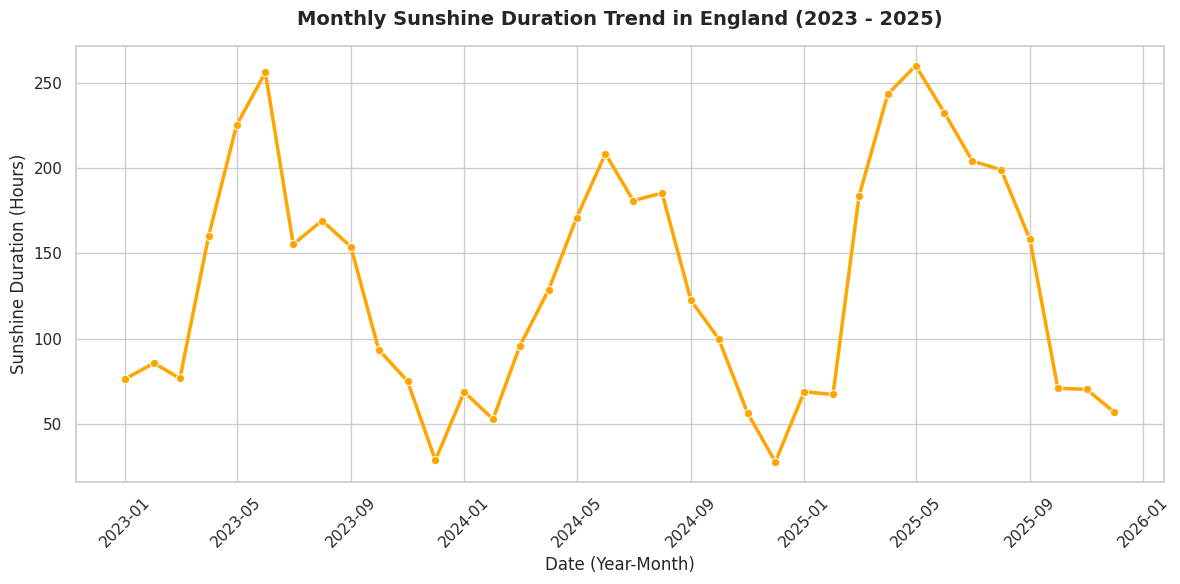

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter the data for the years 2023, 2024, and 2025
df_filtered = df_sunshine[df_sunshine['Year'].isin([2023, 2024, 2025])].copy()

# Sort by Date to ensure chronological order
df_filtered = df_filtered.sort_values('Date')

# Set the figure size and style
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Create the line plot
sns.lineplot(
    data=df_filtered,
    x='Date',
    y='Sunshine duration (hours)',
    marker='o',
    linewidth=2.5,
    color='orange'
)

# Customize the plot
plt.title('Monthly Sunshine Duration Trend in England (2023 - 2025)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Date (Year-Month)', fontsize=12)
plt.ylabel('Sunshine Duration (Hours)', fontsize=12)

# Rotate x-axis labels for readability
plt.xticks(rotation=45)
plt.tight_layout()

# Display the plot
plt.show()

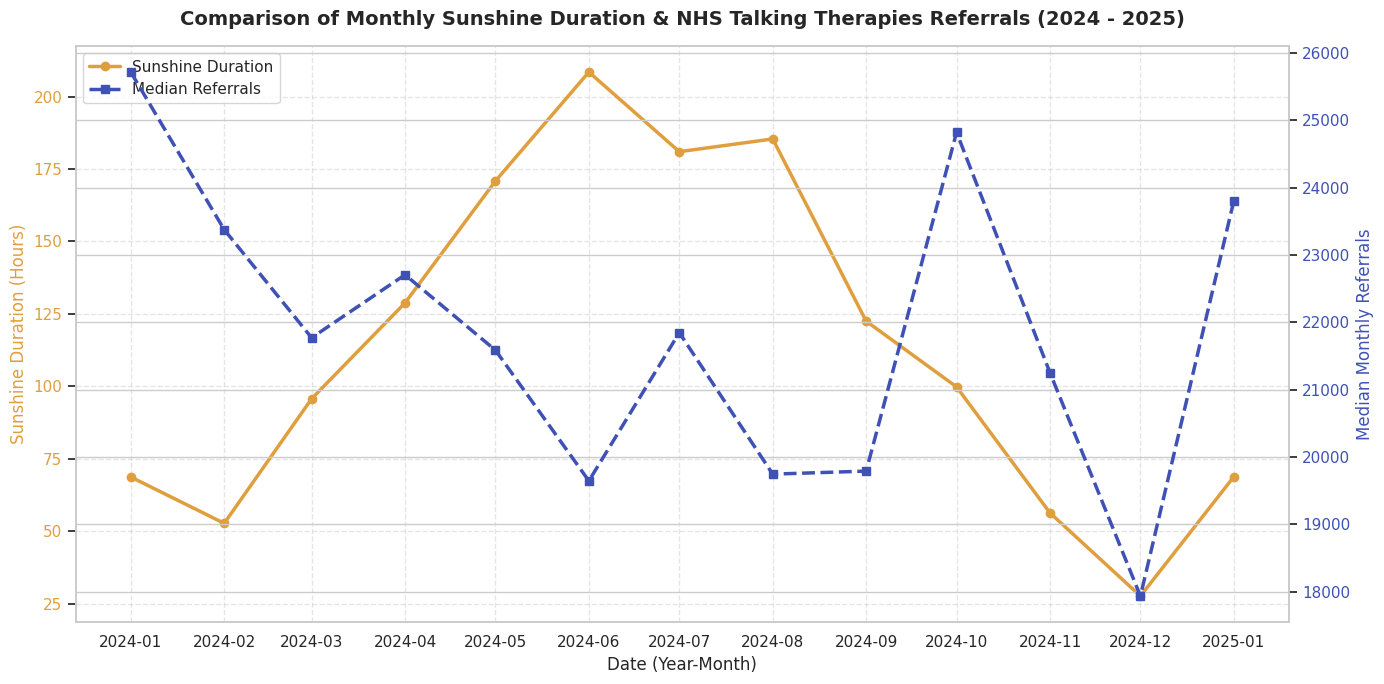

In [6]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Prepare Referral Data (2024 - 2025)
# Calculate the median monthly referrals from the referrals dataframe
monthly_referrals = referrals.groupby('REPORTING_PERIOD_START')['MEASURE_VALUE'].median().reset_index()
monthly_referrals.rename(columns={'REPORTING_PERIOD_START': 'Date', 'MEASURE_VALUE': 'Median_Referrals'}, inplace=True)
monthly_referrals = monthly_referrals[(monthly_referrals['Date'] >= '2024-01-01') & (monthly_referrals['Date'] <= '2025-12-31')]

# 2. Prepare Sunshine Data (2024 - 2025)
monthly_sunshine = df_sunshine[(df_sunshine['Date'] >= '2024-01-01') & (df_sunshine['Date'] <= '2025-12-31')][['Date', 'Sunshine duration (hours)']].copy()

# 3. Merge Datasets on Date
df_merged = pd.merge(monthly_sunshine, monthly_referrals, on='Date', how='inner')
df_merged = df_merged.sort_values('Date')

# 4. Plotting using Dual Axis
fig, ax1 = plt.subplots(figsize=(14, 7))

# Primary Y-axis: Sunshine Duration
color = '#e09f3e'
ax1.set_xlabel('Date (Year-Month)', fontsize=12)
ax1.set_ylabel('Sunshine Duration (Hours)', color=color, fontsize=12)
line1 = ax1.plot(df_merged['Date'], df_merged['Sunshine duration (hours)'], color=color, marker='o', linewidth=2.5, label='Sunshine Duration')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

# Secondary Y-axis: Median Referrals
ax2 = ax1.twinx()
color = '#3f51b5'
ax2.set_ylabel('Median Monthly Referrals', color=color, fontsize=12)
line2 = ax2.plot(df_merged['Date'], df_merged['Median_Referrals'], color=color, marker='s', linestyle='--', linewidth=2.5, label='Median Referrals')
ax2.tick_params(axis='y', labelcolor=color)

# Combine Legends
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', fontsize=11)

plt.title('Comparison of Monthly Sunshine Duration & NHS Talking Therapies Referrals (2024 - 2025)', fontsize=14, fontweight='bold', pad=15)
plt.xticks(df_merged['Date'], df_merged['Date'].dt.strftime('%Y-%m'), rotation=45)
fig.tight_layout()
plt.show()

In [8]:
import pandas as pd

# 1. Load the antidepressant dataset
file_path = 'items for antidepressant drugs per.csv'
df_drugs = pd.read_csv(file_path)

print("Original Columns:", df_drugs.columns.tolist())

# 2. Filter out ONLY 'x_items' and 'x_actual_cost' (or any column starting with 'x_')
cols_to_keep = [col for col in df_drugs.columns if not (col.startswith('x_') or col in ['x-items', 'x-actual cost'])]
df_cleaned = df_drugs[cols_to_keep].copy()

print("Columns after removing x-items and x-actual cost:", df_cleaned.columns.tolist())

# 3. Identify and parse date/time column to filter 2023 ~ 2025
date_col = None
for col in df_cleaned.columns:
    if 'date' in col.lower() or 'period' in col.lower() or 'month' in col.lower():
        date_col = col
        break

if date_col:
    df_cleaned[date_col] = pd.to_datetime(df_cleaned[date_col], errors='coerce')
    # Extract Year and Month
    df_cleaned['Year'] = df_cleaned[date_col].dt.year
    df_cleaned['Month'] = df_cleaned[date_col].dt.month

    # Filter for years 2023 to 2025
    df_filtered_drugs = df_cleaned[df_cleaned['Year'].isin([2023, 2024, 2025])].copy()

    # Find remaining numeric columns to aggregate (excluding Year/Month itself)
    value_cols = [col for col in df_filtered_drugs.select_dtypes(include='number').columns if col not in ['Year', 'Month']]

    # Create a monthly sum dataset
    df_monthly_sum = df_filtered_drugs.groupby(['Year', 'Month'])[value_cols].sum().reset_index()

    # Save the cleaned datasets
    df_cleaned.to_csv('antidepressant_drugs_clean.csv', index=False)
    df_monthly_sum.to_csv('antidepressant_drugs_monthly_sum_2023_2025.csv', index=False)

    print("\n--- Cleaned Monthly Sum (2023 - 2025) Preview ---")
    display(df_monthly_sum.head())
else:
    print("Could not automatically detect a date/period column.")
    display(df_cleaned.head())

Original Columns: ['date', 'id', 'name', 'y_items', 'y_actual_cost', 'x_items', 'x_actual_cost']
Columns after removing x-items and x-actual cost: ['date', 'id', 'name', 'y_items', 'y_actual_cost']

--- Cleaned Monthly Sum (2023 - 2025) Preview ---


,Year,Month,y_items,y_actual_cost
0,2023,1,7308472,19545179.78
1,2023,2,6734088,17487367.17
2,2023,3,7702876,19656644.41
3,2023,4,6896436,17869694.88
4,2023,5,7366399,19125567.09


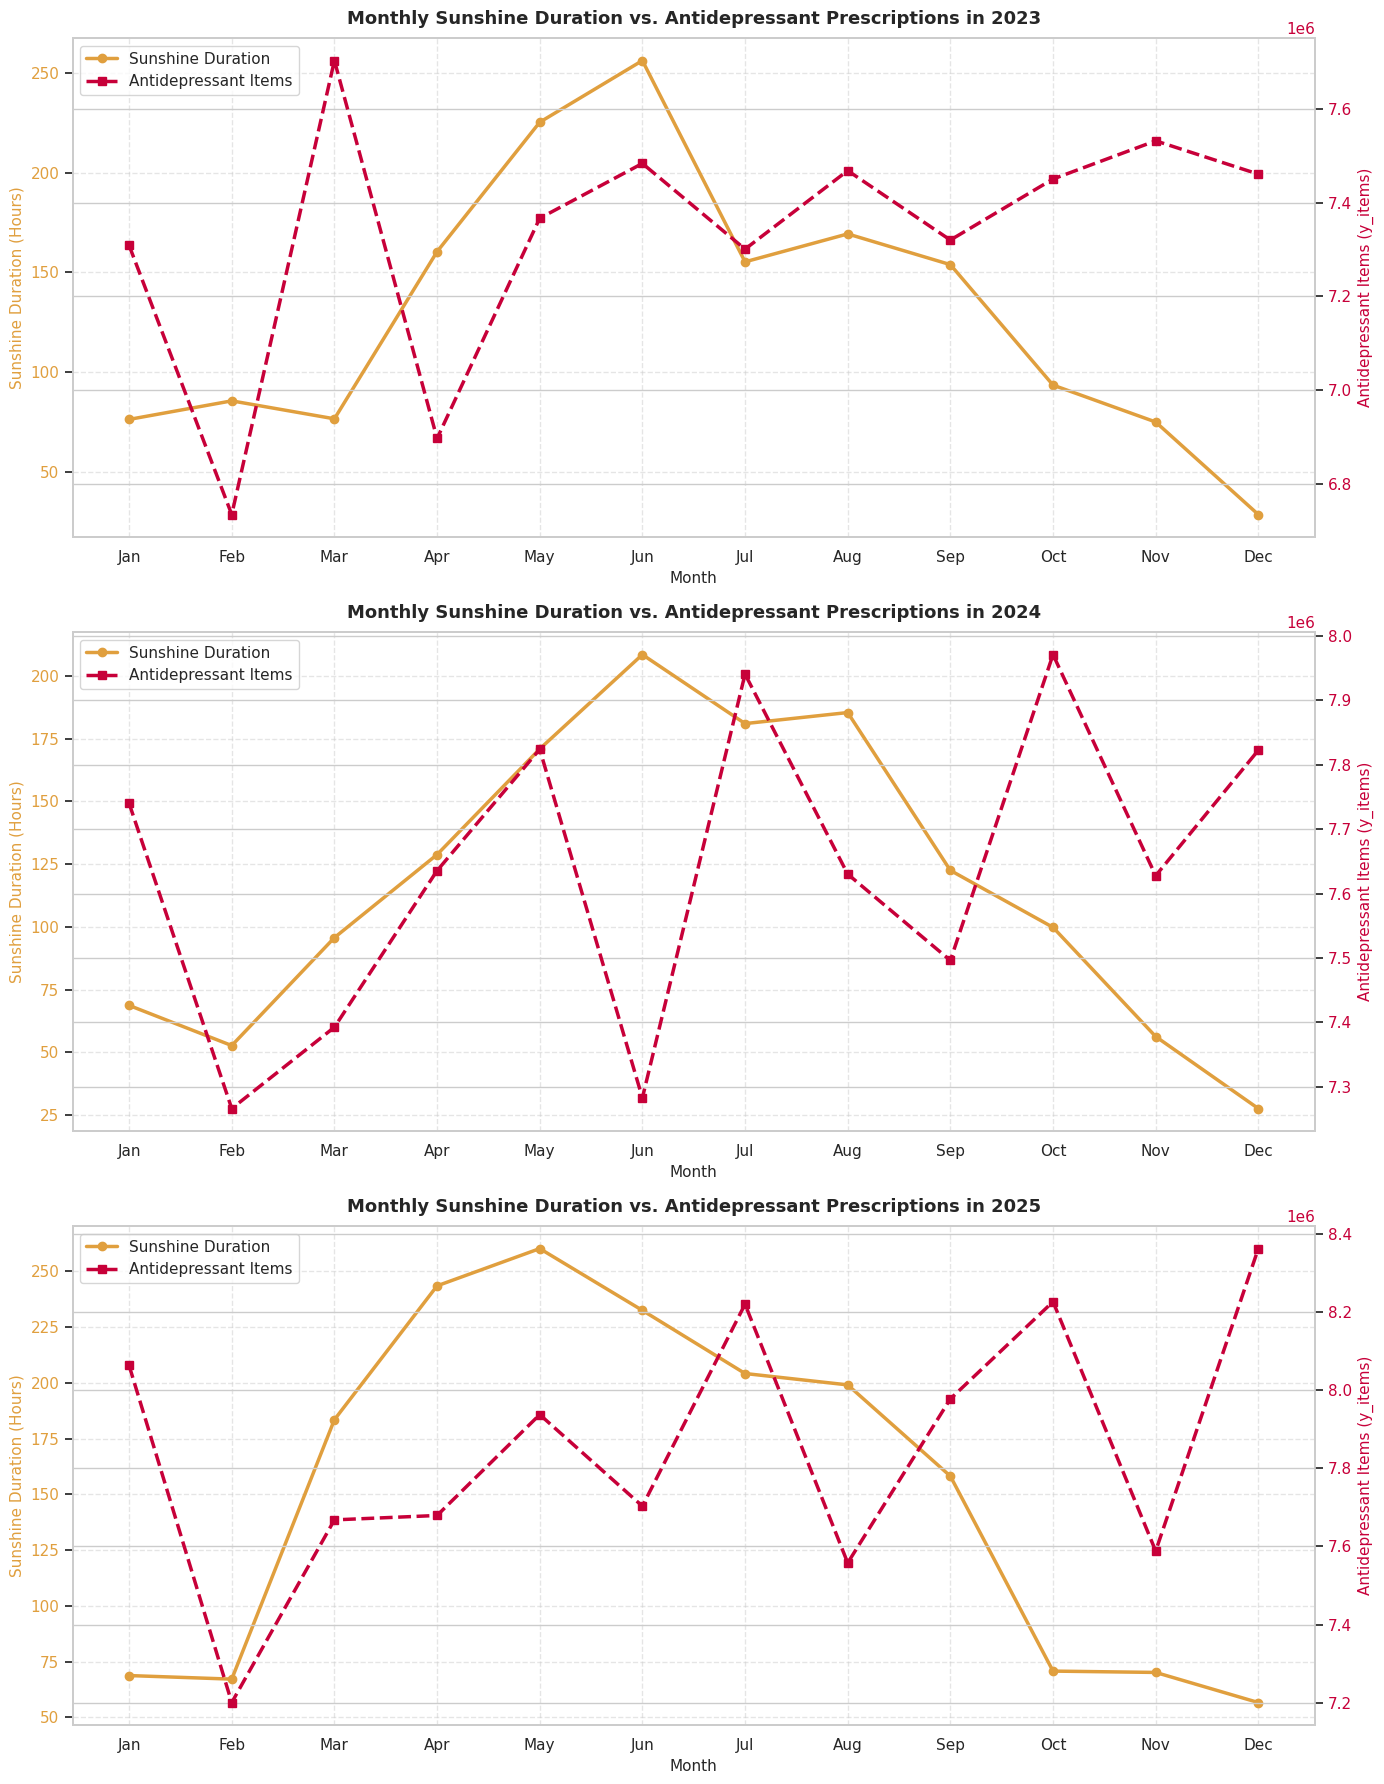

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Prepare Drug Data (2023 - 2025)
df_monthly_sum['Date'] = pd.to_datetime(df_monthly_sum['Year'].astype(str) + '-' + df_monthly_sum['Month'].astype(str) + '-01')

# 2. Prepare Sunshine Data (2023 - 2025)
df_sunshine_filtered = df_sunshine[df_sunshine['Year'].isin([2023, 2024, 2025])][['Date', 'Sunshine duration (hours)']].copy()

# 3. Merge Datasets on Date
df_compare = pd.merge(df_monthly_sum, df_sunshine_filtered, on='Date', how='inner')
df_compare = df_compare.sort_values('Date')

# 4. Create Subplots for each year (2023, 2024, 2025)
years = [2023, 2024, 2025]
fig, axes = plt.subplots(3, 1, figsize=(14, 18), sharex=False)

for i, year in enumerate(years):
    df_year = df_compare[df_compare['Year'] == year]
    ax1 = axes[i]

    # Primary axis: Sunshine Duration
    color_sun = '#e09f3e'
    ax1.set_xlabel('Month', fontsize=11)
    ax1.set_ylabel('Sunshine Duration (Hours)', color=color_sun, fontsize=11)
    line1 = ax1.plot(df_year['Month'], df_year['Sunshine duration (hours)'], color=color_sun, marker='o', linewidth=2.5, label='Sunshine Duration')
    ax1.tick_params(axis='y', labelcolor=color_sun)
    ax1.set_xticks(range(1, 13))
    ax1.set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
    ax1.grid(True, linestyle='--', alpha=0.5)

    # Secondary axis: Antidepressant Items (y_items)
    ax2 = ax1.twinx()
    color_drug = '#c70039'
    ax2.set_ylabel('Antidepressant Items (y_items)', color=color_drug, fontsize=11)
    line2 = ax2.plot(df_year['Month'], df_year['y_items'], color=color_drug, marker='s', linestyle='--', linewidth=2.5, label='Antidepressant Items')
    ax2.tick_params(axis='y', labelcolor=color_drug)

    # Title and Legend
    ax1.set_title(f'Monthly Sunshine Duration vs. Antidepressant Prescriptions in {year}', fontsize=13, fontweight='bold', pad=10)
    lines = line1 + line2
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='upper left')

plt.tight_layout()
plt.show()